# 09 — Duração do vídeo × views

Somente posts de **vídeo** (`content_type == "video"`); `content_length` = duração em segundos.
Figuras exportadas para `docs/figures/` (uso no site).

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from scipy import stats
from social_insights.data import LENGTH_BINS
FIG_DIR = ROOT / "docs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
videos = df[df.content_type == "video"].copy()
videos["faixa de duração"] = videos["length_bin"].astype(str)
print(f"{len(videos):,} vídeos · duração {videos.content_length.min()}–{videos.content_length.max()} s · views {videos.views.min():,}–{videos.views.max():,}")

52,214 posts
31,500 vídeos · duração 10–599 s · views 9,717–10,491


## 1. Histograma 2D: duração × views

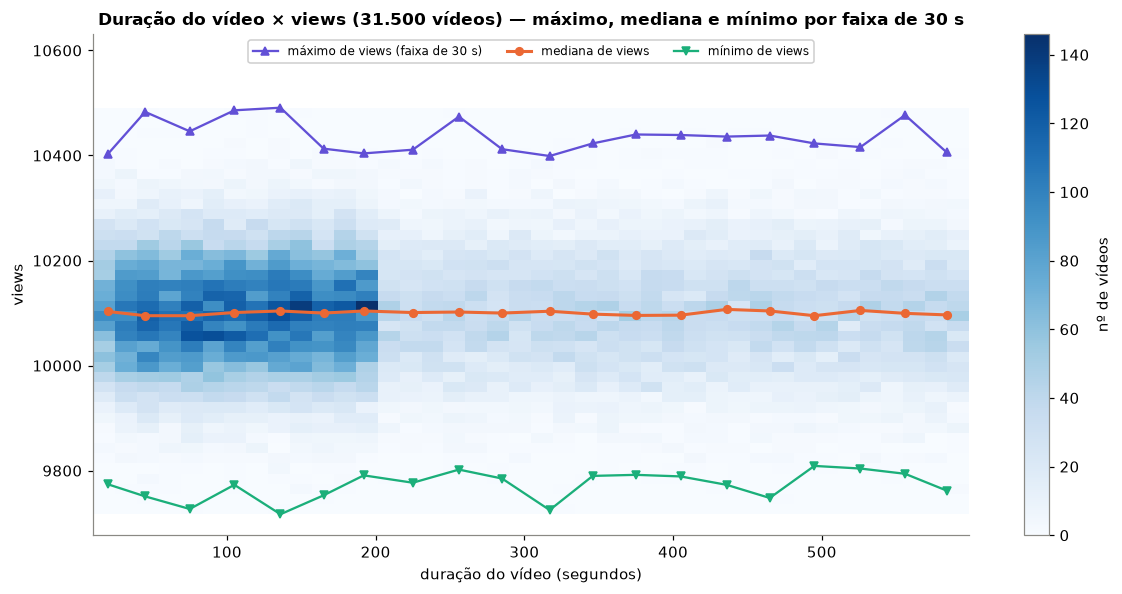

In [2]:
fig, ax = plt.subplots(figsize=(11, 5.5))
counts, xedges, yedges, image = ax.hist2d(videos.content_length, videos.views, bins=[40, 40], cmap="Blues")
fig.colorbar(image, ax=ax, label="nº de vídeos")
bins = pd.cut(videos.content_length, np.arange(0, 630, 30))
per_bin = videos.groupby(bins, observed=True).agg(x=("content_length", "median"), mediana=("views", "median"),
                                                  máximo=("views", "max"), mínimo=("views", "min"), vídeos=("views", "size"))
ax.plot(per_bin.x, per_bin["máximo"], "^-", color="#6250d6", linewidth=1.5, markersize=5, label="máximo de views (faixa de 30 s)")
ax.plot(per_bin.x, per_bin["mediana"], "o-", color=plots.ORANGE, linewidth=2, markersize=5, label="mediana de views")
ax.plot(per_bin.x, per_bin["mínimo"], "v-", color="#1baf7a", linewidth=1.5, markersize=5, label="mínimo de views")
ax.set_xlabel("duração do vídeo (segundos)"); ax.set_ylabel("views")
ax.set_title("Duração do vídeo × views (31.500 vídeos) — máximo, mediana e mínimo por faixa de 30 s")
ax.set_ylim(per_bin["mínimo"].min() - 40, per_bin["máximo"].max() + 140)
ax.legend(loc="upper center", ncol=3, fontsize=8, framealpha=0.95); ax.grid(False)
fig.tight_layout(); fig.savefig(FIG_DIR / "duracao_x_views_hist2d.png", dpi=150); plt.show()

In [3]:
# Extremes depend on how many videos fall in each bin: more draws → higher max and lower min.
per_bin["amplitude (máx − mín)"] = per_bin["máximo"] - per_bin["mínimo"]
rho_n, p_n = stats.spearmanr(per_bin["vídeos"], per_bin["amplitude (máx − mín)"])
display(Markdown(f"**Amplitude × nº de vídeos por faixa:** ρ = {rho_n:+.2f} (p = {p_n:.3f})"))
per_bin.drop(columns="x").rename_axis("faixa (s)")

**Amplitude × nº de vídeos por faixa:** ρ = +0.58 (p = 0.008)

,mediana,máximo,mínimo,vídeos,amplitude (máx − mín)
faixa (s),,,,,
"(0, 30]",10103.0000,10403,9774,1459,629
"(30, 60]",10095.0000,10483,9751,2997,732
"(60, 90]",10095.0000,10446,9727,2965,719
"(90, 120]",10101.0000,10486,9773,2993,713
"(120, 150]",10104.0000,10491,9717,3051,774
"(150, 180]",10100.0000,10413,9753,2948,660
"(180, 210]",10104.0000,10404,9791,2232,613
"(210, 240]",10101.0000,10411,9777,951,634
"(240, 270]",10102.0000,10474,9802,991,672


## 2. Distribuição de views por faixa de duração

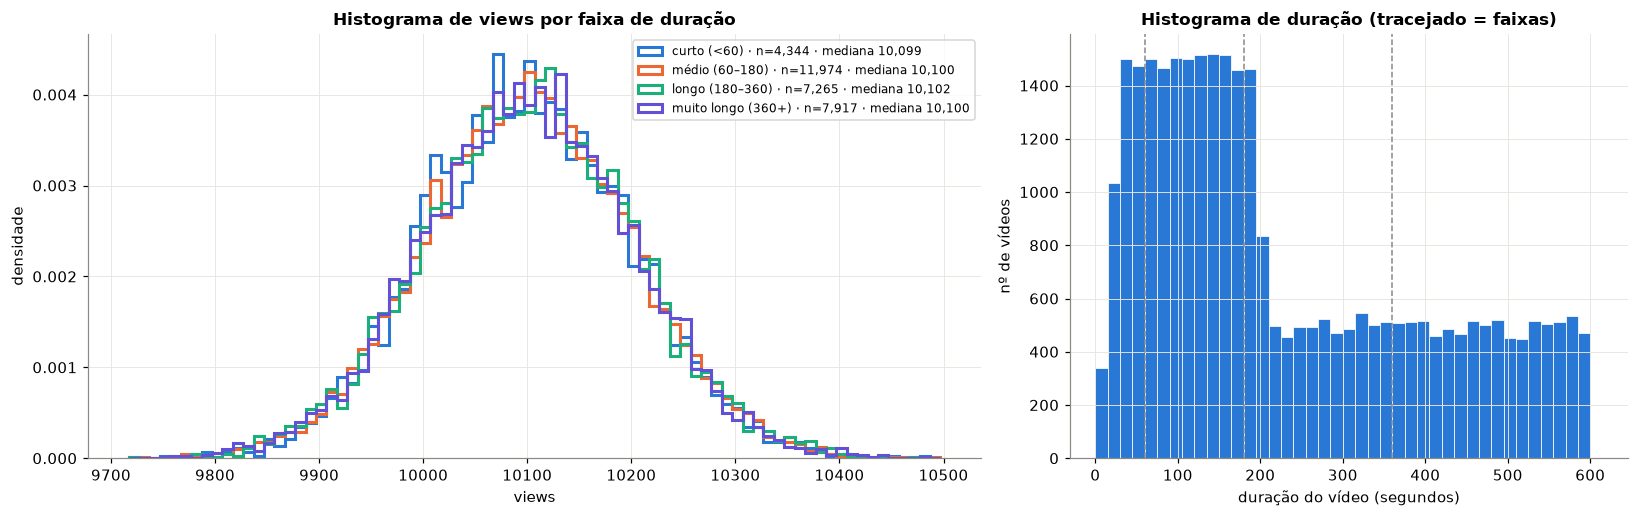

,size,min,mean,median,max,std,vs. média geral (%)
faixa de duração,,,,,,,
curto (<60),4344,9751,10099.7800,10099.0000,10483,98.0700,-0.0100
médio (60–180),11974,9717,10100.6600,10100.0000,10491,100.0600,0.0000
longo (180–360),7265,9725,10100.9400,10102.0000,10474,100.2500,0.0100
muito longo (360+),7917,9748,10099.7200,10100.0000,10477,100.1800,-0.0100


In [4]:
order = list(LENGTH_BINS)
colors = [plots.BLUE, plots.ORANGE, "#1baf7a", "#6250d6"]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})
edges = np.arange(videos.views.min(), videos.views.max() + 10, 10)
for label, color in zip(order, colors):
    v = videos.loc[videos["faixa de duração"] == label, "views"]
    axes[0].hist(v, bins=edges, density=True, histtype="step", linewidth=2, color=color, label=f"{label} · n={len(v):,} · mediana {v.median():,.0f}")
axes[0].set_xlabel("views"); axes[0].set_ylabel("densidade"); axes[0].set_title("Histograma de views por faixa de duração")
axes[0].legend(fontsize=8)
axes[1].hist(videos.content_length, bins=np.arange(0, 630, 15), color=plots.BLUE, edgecolor="white", linewidth=0.5)
for edge in [60, 180, 360]:
    axes[1].axvline(edge, color=plots.GRAY, linestyle="--", linewidth=1)
axes[1].set_xlabel("duração do vídeo (segundos)"); axes[1].set_ylabel("nº de vídeos"); axes[1].set_title("Histograma de duração (tracejado = faixas)")
fig.tight_layout(); fig.savefig(FIG_DIR / "views_por_faixa_de_duracao.png", dpi=150); plt.show()

summary = videos.groupby("faixa de duração")["views"].agg(["size", "min", "mean", "median", "max", "std"]).loc[order]
summary["vs. média geral (%)"] = (summary["mean"] / videos.views.mean() - 1) * 100
summary.round(2)

In [5]:
rho, p = stats.spearmanr(videos.content_length, videos.views)
h, p_kw = stats.kruskal(*[g.values for _, g in videos.groupby("faixa de duração")["views"]])
display(Markdown(f"**Spearman duração × views:** ρ = {rho:+.4f} (p = {p:.2f}) · **Kruskal entre faixas:** p = {p_kw:.2f}"))

**Spearman duração × views:** ρ = +0.0012 (p = 0.83) · **Kruskal entre faixas:** p = 0.83

In [6]:
short, long_ = videos[videos.content_length < 200].views, videos[videos.content_length >= 200].views
display(Markdown(f"**< 200 s:** {len(short):,} vídeos ({len(short) / len(videos):.0%}), média {short.mean():,.1f} views · "
                 f"**≥ 200 s:** {len(long_):,} vídeos, média {long_.mean():,.1f} views · "
                 f"p = {stats.ttest_ind(short, long_, equal_var=False).pvalue:.2f}"))

**< 200 s:** 18,272 vídeos (58%), média 10,100.2 views · **≥ 200 s:** 13,228 vídeos, média 10,100.5 views · p = 0.79

**Leitura:**
- **Duração:** não é uniforme. 58% dos vídeos têm entre ~20 e 200 s (≈ 2,9x mais vídeos por segundo de duração que acima de 200 s), e de 200 a 600 s a distribuição é plana. A mesma forma aparece em imagem, texto e misto, o que confirma que `content_length` não é uma duração real por formato.
- **Histograma 2D:** a mancha mais escura à esquerda é **quantidade de vídeos, não mais views**. Na vertical, a faixa é a mesma em toda duração (~10.000–10.200), e a mediana (laranja) é uma linha reta.
- **Máximos e mínimos:** oscilam de faixa em faixa sem tendência com a duração. As faixas abaixo de 200 s têm extremos um pouco mais abertos só porque têm ~3x mais vídeos (mais sorteios → extremos mais distantes; ver ρ amplitude × nº de vídeos). O pico e o vale de views são **acaso**, não efeito da duração.
- **Histogramas por faixa:** as 4 curvas se sobrepõem, com medianas de 10.099 a 10.102. Spearman ρ = 0,001 e Kruskal p = 0,83; abaixo × acima de 200 s, p = 0,79.
- **Conclusão: a duração do vídeo não muda as views.** Vídeo curto ou longo deve ser escolhido por custo de produção e formato da plataforma, não por alcance esperado.